### Stationarity
Both ACF and PACF assume **stationarity** of the underlying time series. It can be checked via performing Augmented Dickey-Fuller (ADF) test:
- **p-value $\gt$ 0.05** means it failed to reject the null hypothesis (H0) and the data has a unit root and is non-stationary
- **p-value $\leq$ 0.05** means it rejected the null hypothesis (H0), the data does not have a unit root and is stationary

If data isn't stationarity it requires **differiencing**.

In [1]:
import pandas as pd
from utils.paths import DATASETS_PREPROCESSED_DIR
from statsmodels.tsa.stattools import adfuller

df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_train.csv")

result = adfuller(df['delta_p'])

print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
print('Critical Values:')
for key, value in result[4].items():
    print('\t%s: %.3f' % (key, value))

if (result[1] <= 0.05) & (result[4]['5%'] > result[0]):
    print("Stationary")
else:
    print("Non-stationary")

ADF Statistic: -18.438700
p-value: 0.000000
Critical Values:
	1%: -3.431
	5%: -2.862
	10%: -2.567
Stationary


Because ADF Statistic is significantly lower than critical values at 5% level and p-value is lower than 0.05 we can **reject** the null hypothesis (H0) meaning that the data does not have a unit root and is **stationary** and it doesn't require differiencing and we can directly perform ACF and PACF on it.

## Autocorrelation Analysis (ACF and PACF)

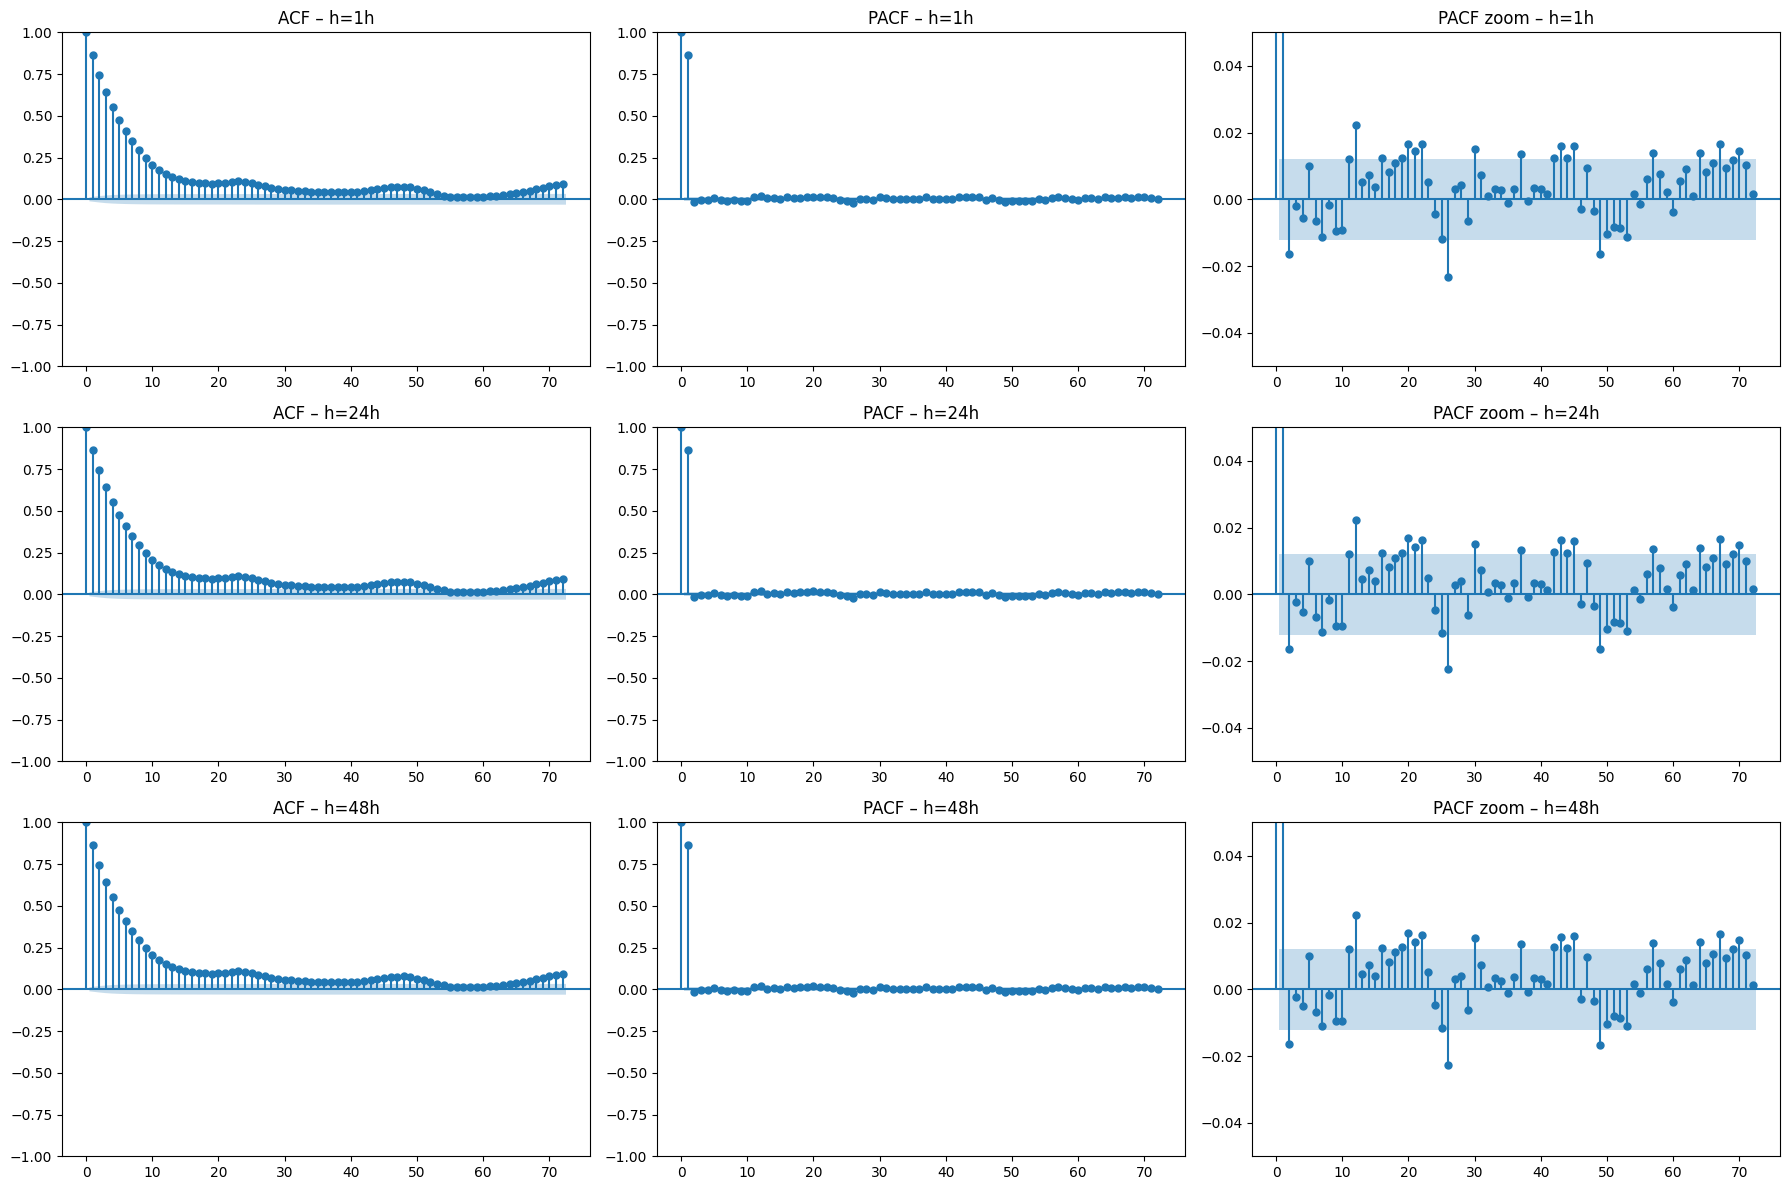

In [2]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

horizons = [1, 24, 48]

fig, axes = plt.subplots(len(horizons), 3, figsize=(18, 12))

for i, horizon in enumerate(horizons):
    target_h = df["delta_p"].shift(-horizon).dropna()

    plot_acf(target_h, lags=72, ax=axes[i, 0])
    axes[i, 0].set_title(f"ACF – h={horizon}h")

    plot_pacf(target_h, lags=72, ax=axes[i, 1], method="ols")
    axes[i, 1].set_title(f"PACF – h={horizon}h")

    plot_pacf(target_h, lags=72, ax=axes[i, 2], method="ols")
    axes[i, 2].set_ylim(-0.05, 0.05)
    axes[i, 2].set_title(f"PACF zoom – h={horizon}h")

plt.tight_layout()
plt.show()

The results of both ACF and PACF indicates that records up to **P(t-72)** are significat for determinig **P(t)**.  

- **ACF** shows that researched time series has a very long correlation, which is showed by slow bar fading and also some wavy patterns meaning there is some seasonality and the value from 24h or 48h might still influence the current value.
- **PACF** show a direct influence of specific moments from the past on the current value. The most crucial ones are from the first 3 lags. Zooming the graph also allowed for identifying some points even right before 48 records from P(t), so the data from a even 2 days ago might directly influence the current value.